### Ejercicio 6 (4 puntos)

Se consideran las funciones:

$$k(x) = x^4 - 2x^3 - 2x, \quad h(x) = \cos(x) - 1$$

**a)** Encontrar el punto de intersección de ambas curvas usando el **método de Traub** con $x_0 = 3$, y una tolerancia de $10^{-12}$, indicar el valor del error, el número de iteraciones y el ACOC que se obtiene. Comparar los resultados obtenidos con el **Método SH4** y el **Método MMC2** (En Python).

**b)** Con el resultado anterior, encontrar el valor de la integral (Integrar en papel y lápiz):

$$\int_{0}^{a} (h(x) - k(x)) \, dx$$

In [4]:
import math
import numpy as np
import pandas as pd

# Formato a 16 decimales
pd.set_option('display.float_format', lambda x: '%.16f' % x)

# Definicion de funciones
f = lambda x: math.cos(x) - 1 - x**4 + 2 * x**3 + 2 * x
df = lambda x: -math.sin(x) - 4 * x**3 + 6 * x**2 + 2


# Metodo de Traub
def traub(f, df, x0, tol, maxiter):
  iters = 0
  error = tol + 1
  x_hist, e_hist = [x0], []

  while error > tol and iters < maxiter:
    y = x0 - f(x0) / df(x0)
    x = y - f(y) / df(x0)

    error = math.fabs(x - x0)
    e_hist.append(error)
    x_hist.append(x)
    iters += 1
    x0 = x

  e = np.array(e_hist)
  acoc = []
  if len(e) >= 3 and np.all(e > 0):
    acoc = np.log(e[2:] / e[1:-1]) / np.log(e[1:-1] / e[:-2])

  return x, iters, error, acoc, x_hist, e_hist


# Metodo SH4
def sh4(f, df, x0, tol, maxiter):
  iters = 0
  error = tol + 1
  x_hist, e_hist = [x0], []

  while error > tol and iters < maxiter:
    fxk, dfxk = f(x0), df(x0)
    y = x0 - fxk / dfxk
    fyk = f(y)

    z = y - (fxk / (fxk - 2 * fyk)) * (fyk / dfxk)
    fzk = f(z)

    x = z - ((fxk + 2 * fyk) / (fxk + 4 * fyk)) * (fzk / dfxk)

    error = math.fabs(x - x0)
    e_hist.append(error)
    x_hist.append(x)
    iters += 1
    x0 = x

  e = np.array(e_hist)
  acoc = []
  if len(e) >= 3 and np.all(e > 0):
    acoc = np.log(e[2:] / e[1:-1]) / np.log(e[1:-1] / e[:-2])

  return x, iters, error, acoc, x_hist, e_hist


# Metodo MMC2
def mmc2(f, df, x0, tol, maxiter):
  iters = 0
  error = tol + 1
  x_hist, e_hist = [x0], []

  while error > tol and iters < maxiter:
    fxk, dfxk = f(x0), df(x0)
    y = x0 - fxk / dfxk
    fyk = f(y)

    if fxk - fyk == 0:
      break

    z = y - (fxk / (fxk - 2 * fyk)) * (fyk / dfxk)
    fzk = f(z)

    t1 = 2 + 3 * (fyk / fxk) - (fxk / (fxk - fyk))
    t2 = fzk / dfxk
    x = z - t1 * t2

    error = math.fabs(x - x0)
    e_hist.append(error)
    x_hist.append(x)
    iters += 1
    x0 = x

  e = np.array(e_hist)
  acoc = []
  if len(e) >= 3 and np.all(e > 0):
    acoc = np.log(e[2:] / e[1:-1]) / np.log(e[1:-1] / e[:-2])

  return x, iters, error, acoc, x_hist, e_hist


# Parametros iniciales
x0 = 3.0
tol = 1e-12
maxiter = 50

# Ejecucion
sol_t, it_t, err_t, acoc_t, x_h_t, e_h_t = traub(f, df, x0, tol, maxiter)
sol_s, it_s, err_s, acoc_s, x_h_s, e_h_s = sh4(f, df, x0, tol, maxiter)
sol_m, it_m, err_m, acoc_m, x_h_m, e_h_m = mmc2(f, df, x0, tol, maxiter)

# Impresion de resultados
print("--- RESULTADOS ---")
print(
    f"TRAUB -> Punto a: {sol_t:.16f} | Iteraciones: {it_t} | Error:"
    f" {err_t:.16e}"
)
print(f"         ACOC: {np.round(acoc_t, 4)}")

print(
    f"SH4   -> Punto a: {sol_s:.16f} | Iteraciones: {it_s} | Error:"
    f" {err_s:.16e}"
)
print(f"         ACOC: {acoc_s}")

print(
    f"MMC2  -> Punto a: {sol_m:.16f} | Iteraciones: {it_m} | Error:"
    f" {err_m:.16e}"
)
print(f"         ACOC: {acoc_m}")

# Tabla para el metodo de Traub
tabla_traub = pd.DataFrame({
    "Iteracion": list(range(1, it_t + 1)),
    "x_k": x_h_t[1:],
    "Error": e_h_t,
})

print("\nTabla de Traub:")
print(tabla_traub.to_string(index=False))

--- RESULTADOS ---
TRAUB -> Punto a: 2.2517271535755685 | Iteraciones: 5 | Error: 4.4408920985006262e-16
         ACOC: [2.5358 2.8504 2.7712]
SH4   -> Punto a: 2.2517271535755685 | Iteraciones: 4 | Error: 0.0000000000000000e+00
         ACOC: []
MMC2  -> Punto a: 2.2517271535755685 | Iteraciones: 3 | Error: 1.3737693205229107e-08
         ACOC: [4.87878428]

Tabla de Traub:
 Iteracion                x_k              Error
         1 2.4423470798315905 0.5576529201684095
         2 2.2620270157675204 0.1803200640640701
         3 2.2517300960436337 0.0102969197238867
         4 2.2517271535755690 0.0000029424680648
         5 2.2517271535755685 0.0000000000000004


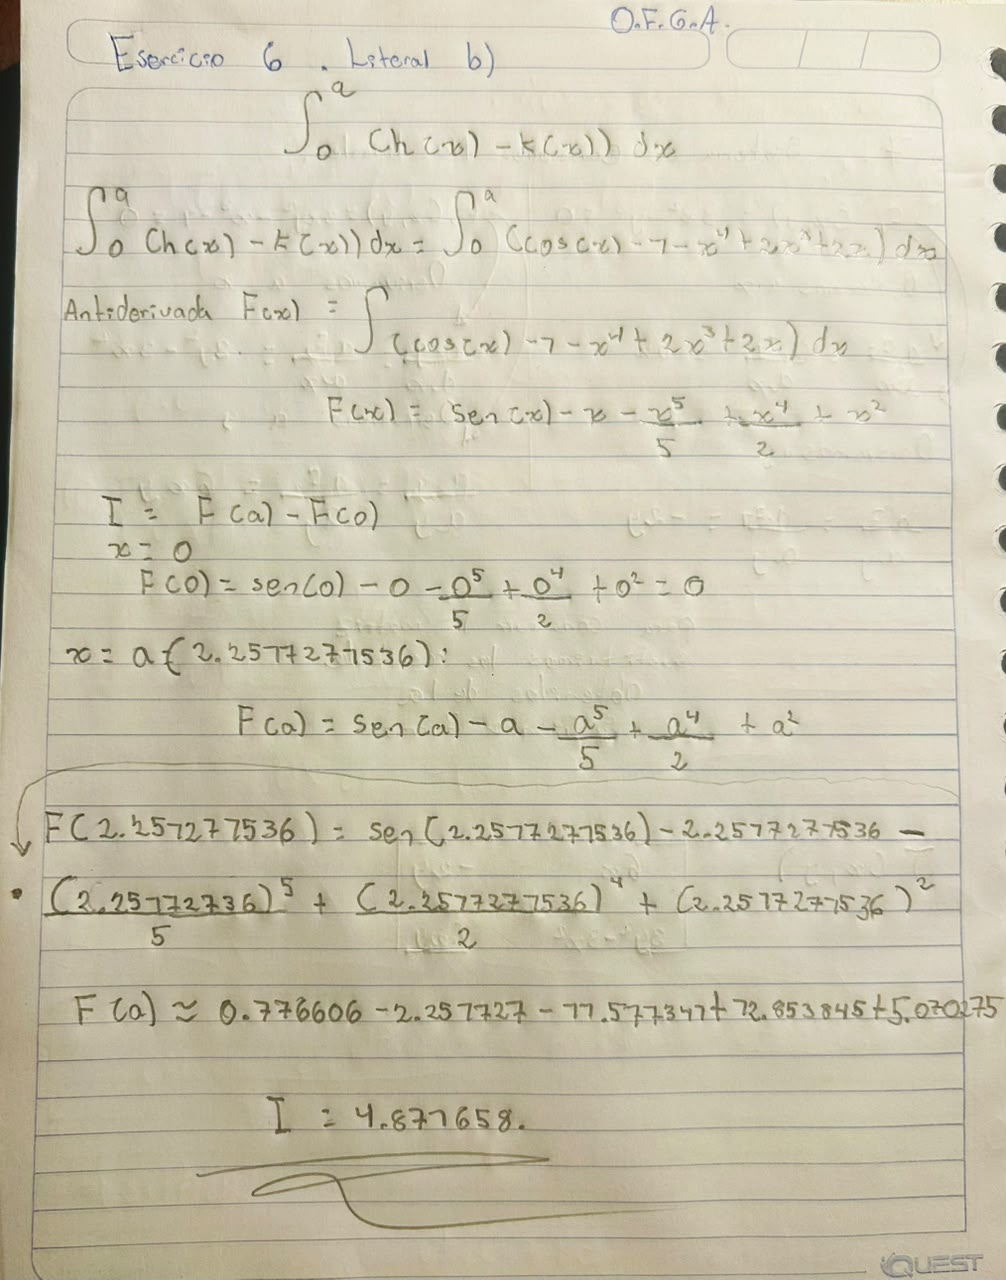